Çalışma Ortamı Cihazı: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 39.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.03MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.5MB/s]


Veri Kümesi Boyutları -> Train: 50000 | Validation: 10000 | Test: 10000

--- Başlıyor: Deney 1: Temel MLP (Adam) ---
Epoch [01/10] | Train Loss: 0.2492, Train Acc: %92.50 | Val Loss: 0.1343, Val Acc: %95.99
Epoch [02/10] | Train Loss: 0.1017, Train Acc: %96.86 | Val Loss: 0.1147, Val Acc: %96.59
Epoch [03/10] | Train Loss: 0.0698, Train Acc: %97.77 | Val Loss: 0.0979, Val Acc: %96.92
Epoch [04/10] | Train Loss: 0.0512, Train Acc: %98.35 | Val Loss: 0.1121, Val Acc: %96.66
Epoch [05/10] | Train Loss: 0.0421, Train Acc: %98.61 | Val Loss: 0.0973, Val Acc: %97.36
Epoch [06/10] | Train Loss: 0.0334, Train Acc: %98.91 | Val Loss: 0.1066, Val Acc: %97.25
Epoch [07/10] | Train Loss: 0.0288, Train Acc: %99.06 | Val Loss: 0.1038, Val Acc: %97.29
Epoch [08/10] | Train Loss: 0.0240, Train Acc: %99.18 | Val Loss: 0.0965, Val Acc: %97.58
Epoch [09/10] | Train Loss: 0.0244, Train Acc: %99.24 | Val Loss: 0.1004, Val Acc: %97.54
Epoch [10/10] | Train Loss: 0.0192, Train Acc: %99.37 | Val Loss: 0.1074,

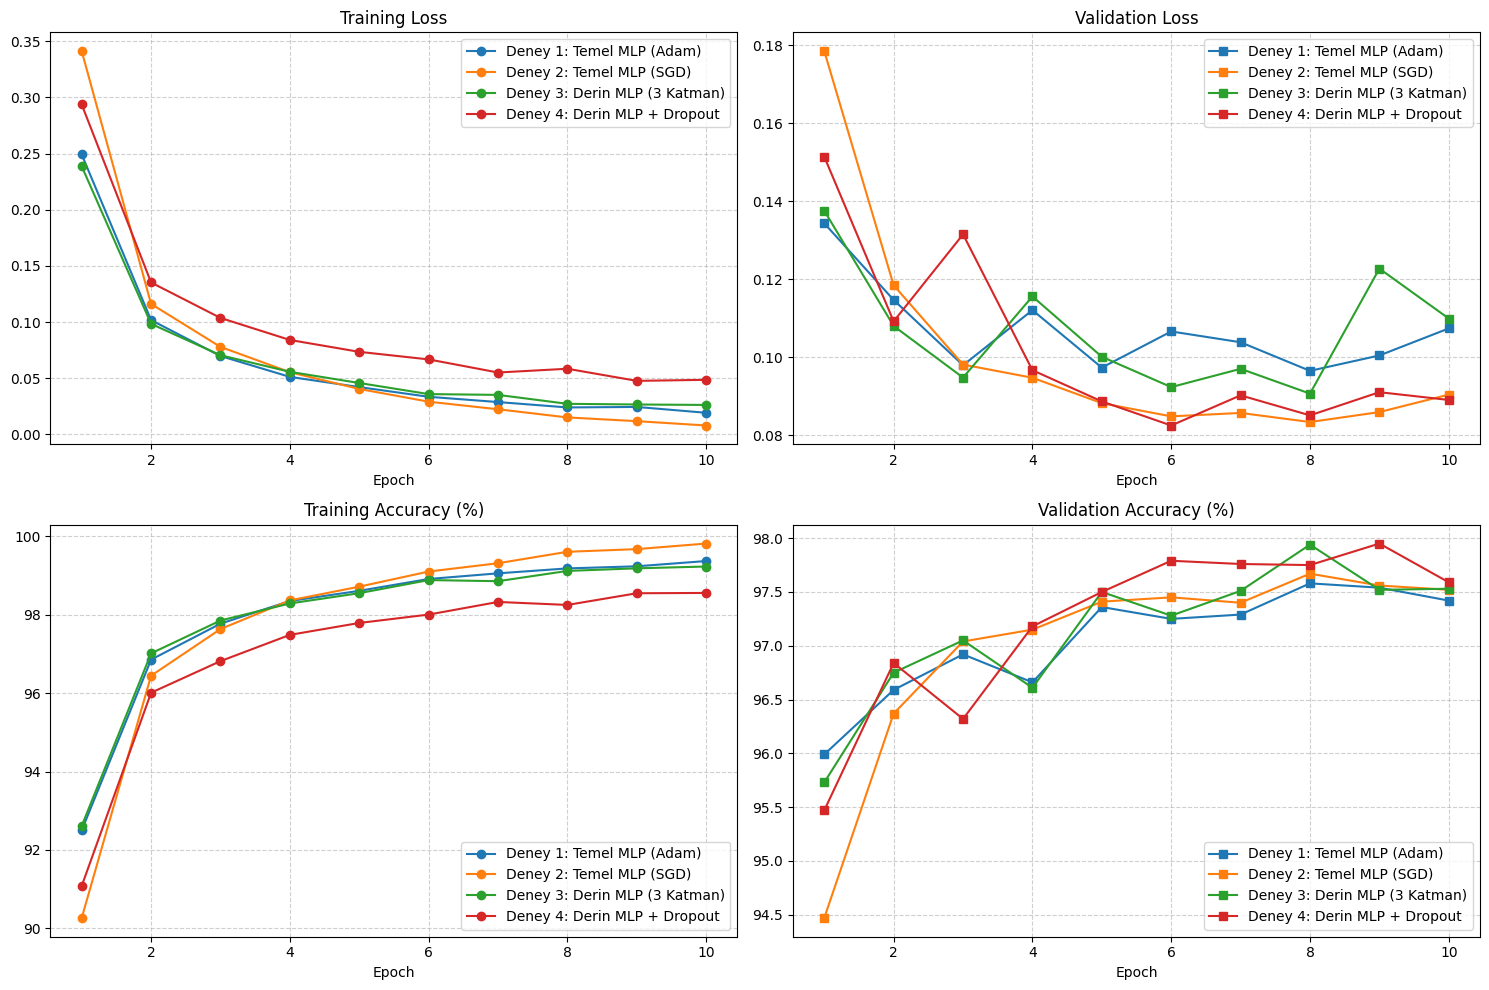

In [ ]:
import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import pandas as pd

# Sonuçların tekrarlanabilirliği (Reproducibility) için sabit tohum
SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Çalışma Ortamı Cihazı: {device}")

os.makedirs("results", exist_ok=True)

# ==========================================
# 1. VERİ SETİ VE TRAIN / VAL / TEST AYRIMI
# ==========================================
# MNIST standart normalizasyon değerleri (mean=0.1307, std=0.3081)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# 60.000 eğitim verisini -> 50.000 Train ve 10.000 Validation olarak ayırıyoruz
train_size = 50000
val_size = 10000
train_dataset, val_dataset = random_split(
    full_train_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Veri Kümesi Boyutları -> Train: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}")

# ==========================================
# 2. ESNEK MLP MİMARİSİ (CNN KESİNLİKLE YOK)
# ==========================================
class MLP(nn.Module):
    def __init__(self, hidden_dims=[256, 128], dropout_rate=0.0):
        super(MLP, self).__init__()
        layers = [nn.Flatten()] # 28x28 görüntüyü 784 boyutlu vektöre düzleştirir
        input_dim = 28 * 28

        for h_dim in hidden_dims:
            layers.append(nn.Linear(input_dim, h_dim))
            layers.append(nn.ReLU()) # Talimat gereği ReLU aktivasyonu
            if dropout_rate > 0.0:
                layers.append(nn.Dropout(dropout_rate))
            input_dim = h_dim

        layers.append(nn.Linear(input_dim, 10)) # 10 sınıf (0-9 rakamları)
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# ==========================================
# 3. EĞİTİM VE DEĞERLENDİRME FONKSİYONLARI
# ==========================================
def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return running_loss / total, (correct / total) * 100.0

def train_experiment(exp_config, epochs=10):
    print(f"\n--- Başlıyor: {exp_config['name']} ---")
    model = MLP(
        hidden_dims=exp_config["hidden_dims"],
        dropout_rate=exp_config["dropout"]
    ).to(device)

    criterion = nn.CrossEntropyLoss()

    if exp_config["optimizer"] == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=exp_config["lr"])
    elif exp_config["optimizer"] == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=exp_config["lr"], momentum=0.9)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_model_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_acc = (correct / total) * 100.0
        val_loss, val_acc = evaluate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_weights = copy.deepcopy(model.state_dict())

        print(f"Epoch [{epoch:02d}/{epochs:02d}] | "
              f"Train Loss: {train_loss:.4f}, Train Acc: %{train_acc:.2f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: %{val_acc:.2f}")

    elapsed_time = time.time() - start_time

    # En iyi validation ağırlıklarını yükleyip TEST verisi üzerinde (yalnızca 1 kez) değerlendiriyoruz
    model.load_state_dict(best_model_weights)
    test_loss, test_acc = evaluate(model, test_loader, criterion)

    print(f"--> {exp_config['name']} Tamamlandı | Süre: {elapsed_time:.2f} sn | Test Acc: %{test_acc:.2f}")

    return model, history, {
        "Deney Adı": exp_config["name"],
        "Gizli Katmanlar": str(exp_config["hidden_dims"]),
        "Optimizer": exp_config["optimizer"],
        "Learning Rate": exp_config["lr"],
        "Dropout": exp_config["dropout"],
        "Train Loss": round(history["train_loss"][-1], 4),
        "Val Loss": round(history["val_loss"][-1], 4),
        "Train Acc (%)": round(history["train_acc"][-1], 2),
        "Val Acc (%)": round(best_val_acc, 2),
        "Test Acc (%)": round(test_acc, 2),
        "Eğitim Süresi (sn)": round(elapsed_time, 2)
    }

# ==========================================
# 4. DENEY MATRİSİNİN ÇALIŞTIRILMASI
# ==========================================
experiments = [
    {"name": "Deney 1: Temel MLP (Adam)",       "hidden_dims": [256, 128],      "optimizer": "Adam", "lr": 0.001, "dropout": 0.0},
    {"name": "Deney 2: Temel MLP (SGD)",        "hidden_dims": [256, 128],      "optimizer": "SGD",  "lr": 0.01,  "dropout": 0.0},
    {"name": "Deney 3: Derin MLP (3 Katman)",   "hidden_dims": [512, 256, 128], "optimizer": "Adam", "lr": 0.001, "dropout": 0.0},
    {"name": "Deney 4: Derin MLP + Dropout",    "hidden_dims": [512, 256, 128], "optimizer": "Adam", "lr": 0.001, "dropout": 0.2},
]

EPOCHS = 10
all_histories = {}
summary_results = []
trained_models = {}

for exp in experiments:
    model, hist, metrics = train_experiment(exp, epochs=EPOCHS)
    all_histories[exp["name"]] = hist
    summary_results.append(metrics)
    trained_models[exp["name"]] = model

# Sonuç Tablosunu Göster ve Kaydet
results_df = pd.DataFrame(summary_results)
print("\n=== DENEY SONUÇLARI ÖZET TABLOSU ===")
print(results_df.to_markdown(index=False))

# En yüksek Validation başarısına sahip modeli seç
best_exp_name = results_df.loc[results_df["Val Acc (%)"].idxmax(), "Deney Adı"]
best_model = trained_models[best_exp_name]
torch.save(best_model.state_dict(), "results/best_mlp_mnist.pth")
print(f"\nEl yazısı testi için seçilen en iyi model: {best_exp_name}")

# ==========================================
# 5. LOSS VE ACCURACY GRAFİKLERİNİN ÇİZİMİ
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
epochs_range = range(1, EPOCHS + 1)

for name, hist in all_histories.items():
    axes[0, 0].plot(epochs_range, hist["train_loss"], marker='o', label=name)
    axes[0, 1].plot(epochs_range, hist["val_loss"], marker='s', label=name)
    axes[1, 0].plot(epochs_range, hist["train_acc"], marker='o', label=name)
    axes[1, 1].plot(epochs_range, hist["val_acc"], marker='s', label=name)

axes[0, 0].set_title("Training Loss")
axes[0, 1].set_title("Validation Loss")
axes[1, 0].set_title("Training Accuracy (%)")
axes[1, 1].set_title("Validation Accuracy (%)")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.savefig("results/learning_curves.png", dpi=300)
plt.show()

In [ ]:
import cv2
import glob
import numpy as np
from scipy.ndimage import center_of_mass

# ========================================================
# BURAYA KENDİ ÖĞRENCİ NUMARANI GİR (Örn: "220201055")
# ========================================================
STUDENT_ID = "24120205012"

def mnist_standard_preprocess(gray_img):
    """
    Gerçek dünya el yazısı görüntüsünü MNIST formatına (20x20 kutu içinde
    kütle merkezine göre 28x28 tuvale hizalanmış, siyah zemin / beyaz yazı) dönüştürür.
    """
    # 1. Gürültü azaltma ve Otsu/Adaptive ikili eşikleme (Arka plan siyah=0, Rakam beyaz=255)
    blurred = cv2.GaussianBlur(gray_img, (5, 5), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 2. Rakamın etrafındaki gereksiz boşlukları kırp (Bounding Box)
    coords = cv2.findNonZero(thresh)
    if coords is None:
        return np.zeros((28, 28), dtype=np.float32)
    x, y, w, h = cv2.boundingRect(coords)
    cropped = thresh[y:y+h, x:x+w]

    # 3. En-boy oranını koruyarak en uzun kenarı 20 piksel olacak şekilde ölçekle
    if w > h:
        new_w = 20
        new_h = max(1, int(round((20.0 / w) * h)))
    else:
        new_h = 20
        new_w = max(1, int(round((20.0 / h) * w)))
    resized = cv2.resize(cropped, (new_w, new_h), interpolation=cv2.INTER_AREA)

    # 4. 28x28 siyah tuvalin ortasına yerleştir (Padding)
    canvas = np.zeros((28, 28), dtype=np.uint8)
    pad_top = (28 - new_h) // 2
    pad_left = (28 - new_w) // 2
    canvas[pad_top:pad_top+new_h, pad_left:pad_left+new_w] = resized

    # 5. Kütle merkezine (Center of Mass) göre kaydır
    cy, cx = center_of_mass(canvas)
    if not np.isnan(cy) and not np.isnan(cx):
        shift_x = np.round(14.0 - cx).astype(int)
        shift_y = np.round(14.0 - cy).astype(int)
        M = np.float32([[1, 0, shift_x], [0, 1, shift_y]])
        canvas = cv2.warpAffine(canvas, M, (28, 28))

    # 6. [0, 1] aralığına çek ve MNIST mean/std ile normalize et
    norm_img = canvas.astype(np.float32) / 255.0
    norm_img = (norm_img - 0.1307) / 0.3081
    return canvas, norm_img

def extract_digits_from_single_sheet(image_path, expected_count=None):
    """
    Tek bir kağıda yan yana yazılmış öğrenci numarasındaki rakamları soldan sağa ayırır.
    """
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Görsel bulunamadı: {image_path}")

    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 19, 9)

    # Kopuk çizgileri birleştirmek için hafif morfolojik kapama
    kernel = np.ones((3, 3), np.uint8)
    thresh = cv2.dilate(thresh, kernel, iterations=1)

    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if h > 15 and w > 5: # Küçük toz/gürültü noktalarını filtrele
            boxes.append((x, y, w, h))

    # Soldan sağa sırala
    boxes = sorted(boxes, key=lambda b: b[0])

    digit_crops = []
    for (x, y, w, h) in boxes:
        margin = 6
        y1, y2 = max(0, y - margin), min(img.shape[0], y + h + margin)
        x1, x2 = max(0, x - margin), min(img.shape[1], x + w + margin)
        digit_crops.append(img[y1:y2, x1:x2])

    return digit_crops

def predict_student_id(model, digit_gray_list, student_id_str):
    model.eval()
    n = len(digit_gray_list)
    fig, axes = plt.subplots(2, n, figsize=(2 * n, 4.5))
    if n == 1:
        axes = np.expand_dims(axes, axis=1)

    correct_count = 0
    predictions = []

    for idx, gray_crop in enumerate(digit_gray_list):
        canvas_28, norm_tensor_np = mnist_standard_preprocess(gray_crop)
        input_tensor = torch.tensor(norm_tensor_np).unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(input_tensor)
            probs = torch.softmax(logits, dim=1)
            conf, pred = torch.max(probs, dim=1)
            pred_digit = pred.item()
            confidence = conf.item() * 100.0

        predictions.append(str(pred_digit))
        true_digit = int(student_id_str[idx]) if idx < len(student_id_str) else None
        is_correct = (pred_digit == true_digit)
        if is_correct:
            correct_count += 1

        # Üst satır: Ham gri kırpım | Alt satır: 28x28 MNIST formatına getirilmiş görüntü
        axes[0, idx].imshow(gray_crop, cmap="gray")
        axes[0, idx].set_title(f"Ham #{idx+1}")
        axes[0, idx].axis("off")

        color = "green" if is_correct else "red"
        axes[1, idx].imshow(canvas_28, cmap="gray")
        axes[1, idx].set_title(f"Tahmin: {pred_digit}\n(%{confidence:.1f})", color=color, fontweight="bold")
        axes[1, idx].axis("off")

    plt.suptitle(f"Öğrenci No: {student_id_str} | Tahmin: {''.join(predictions)} | Başarı: {correct_count}/{len(student_id_str)}", fontsize=14)
    plt.tight_layout()
    plt.savefig("results/handwriting_predictions.png", dpi=300)
    plt.show()

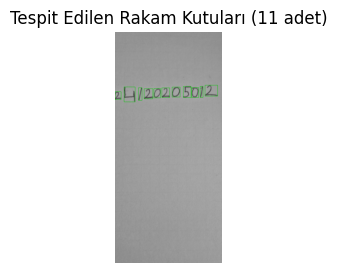

Başarılı: Tam olarak 11 adet rakam ayrıştırıldı.


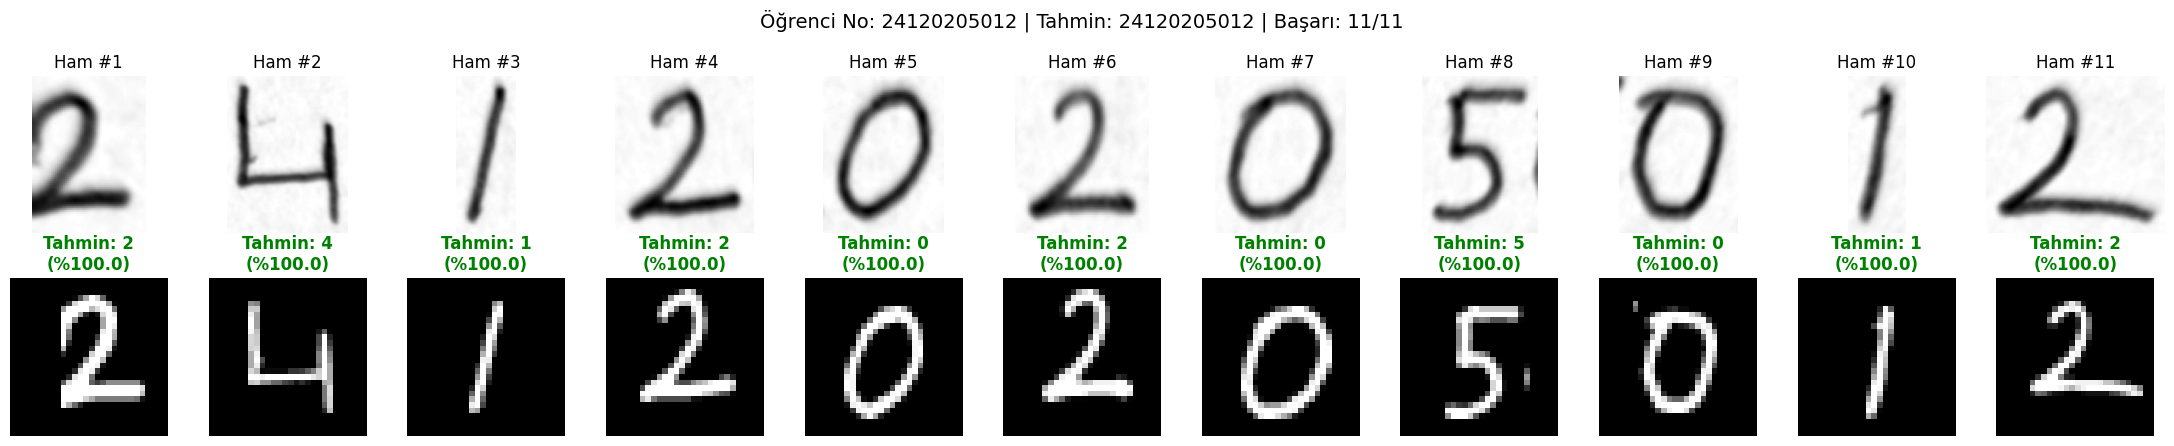

In [ ]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import center_of_mass

# ========================================================
# 1. BURAYI KENDİ BİLGİLERİNE GÖRE DÜZENLE
# ========================================================
DOSYA_ADI = "numaram.jpg"    # Sol panele yüklediğin fotoğrafın adı
OGRENCI_NO = "24120205012"     # Kağıda yazdığın kendi öğrenci numaran

def extract_digits_robust(image_path, expected_digits):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Görsel bulunamadı: {image_path}")

    # 1. Yüksek çözünürlüklü telefon fotoğrafını standart genişliğe (1000px) ölçekle
    h_orig, w_orig = img.shape
    target_w = 1000
    scale = target_w / float(w_orig)
    img = cv2.resize(img, (target_w, int(h_orig * scale)), interpolation=cv2.INTER_AREA)

    # 2. Kenarlardaki masa/çerçeve gölgelerini atmak için %5 içeriden kırp
    h, w = img.shape
    margin_y, margin_x = int(h * 0.05), int(w * 0.05)
    img = img[margin_y:h-margin_y, margin_x:w-margin_x]

    # 3. Arka plan aydınlatma/gölge farklarını morfolojik kapama ile düzelt ve Otsu uygula
    blurred = cv2.GaussianBlur(img, (7, 7), 0)
    bg = cv2.morphologyEx(blurred, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51)))
    norm_illumination = cv2.divide(blurred, bg, scale=255)
    _, thresh = cv2.threshold(norm_illumination, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # 4. Aynı rakamın kopuk çizgilerini birleştir (parçalanmayı önler)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (7, 13))
    connected = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=1)

    # 5. Aday kutuları bul ve gürültüleri filtrele
    contours, _ = cv2.findContours(connected, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidate_boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        area = bw * bh
        # Çok küçük tozları veya tüm kağıdı kaplayan dev gölgeleri ele
        if bh > 25 and bw > 8 and bh < img.shape[0] * 0.85 and bw < img.shape[1] * 0.35:
            candidate_boxes.append((x, y, bw, bh, area))

    # 6. Yatayda üst üste binen parçalar varsa tek rakam olarak birleştir
    candidate_boxes = sorted(candidate_boxes, key=lambda b: b[0])
    merged_boxes = []
    for box in candidate_boxes:
        if not merged_boxes:
            merged_boxes.append(box)
        else:
            px, py, pw, ph, parea = merged_boxes[-1]
            cx, cy, cw, ch, carea = box
            overlap_x = min(px + pw, cx + cw) - max(px, cx)
            if overlap_x > -4:
                nx = min(px, cx)
                ny = min(py, cy)
                nw = max(px + pw, cx + cw) - nx
                nh = max(py + ph, cy + ch) - ny
                merged_boxes[-1] = (nx, ny, nw, nh, nw * nh)
            else:
                merged_boxes.append(box)

    # 7. En belirgin N kutuyu seç (Öğrenci numarası hane sayısı kadar) ve soldan sağa sırala
    merged_boxes = sorted(merged_boxes, key=lambda b: b[4], reverse=True)[:expected_digits]
    final_boxes = sorted(merged_boxes, key=lambda b: b[0])

    # Kontrol amaçlı tespit edilen kutuları çizdir
    debug_img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    digit_crops = []
    for (x, y, bw, bh, _) in final_boxes:
        cv2.rectangle(debug_img, (x, y), (x + bw, y + bh), (0, 200, 0), 2)
        pad = 8
        y1, y2 = max(0, y - pad), min(img.shape[0], y + bh + pad)
        x1, x2 = max(0, x - pad), min(img.shape[1], x + bw + pad)
        digit_crops.append(norm_illumination[y1:y2, x1:x2])

    plt.figure(figsize=(10, 3))
    plt.imshow(debug_img)
    plt.title(f"Tespit Edilen Rakam Kutuları ({len(digit_crops)} adet)")
    plt.axis("off")
    plt.show()

    return digit_crops

# Çalıştır ve Tahmin Et
digit_crops = extract_digits_robust(DOSYA_ADI, expected_digits=len(OGRENCI_NO))
print(f"Başarılı: Tam olarak {len(digit_crops)} adet rakam ayrıştırıldı.")
predict_student_id(best_model, digit_crops, OGRENCI_NO)